# Avaliação final no YouTube: todos os modelos

Junta, no mesmo gabarito do YouTube, os modelos das etapas 2, 4 e 5:

| Modelo | Etapa | Onde rodou |
|---|---|---|
| TF-IDF + Regressão Logística | 2 | aqui (retreinado, leva menos de 1 s) |
| BiGRU + NILC GloVe ajustado | 4 | aqui (modelo salvo em `models/`) |
| XLM-R de tweets (zero-shot), BERTimbau congelado + RL, BERTimbau ajustado (3 sementes) | 5 | Colab, notebook `05_transformers.ipynb` (predições em `reports/05_predicoes_youtube.csv`) |

**Gabarito:** os 216 itens em que os dois rotuladores concordaram (kappa geral de 0,48; 0,63 só na polaridade). Os textos ficam em `coleta_youtube/dados/` (fora do git, pelos termos de uso da API); aqui só aparecem contagens e métricas.

**Duas partes**, como na nota de limitações:
1. **Sentimento** nos comentários que os dois rotuladores marcaram como positivo, neutro ou negativo (e nos títulos, à parte).
2. **Ruído:** que classe cada modelo atribui aos comentários marcados "não é sobre o produto", já que nenhum deles tem essa classe.

In [1]:
import sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix, ConfusionMatrixDisplay

RAIZ = Path("..").resolve()
sys.path.insert(0, str(RAIZ))
from src.dados import carregar_repro, dividir_treino_teste, limpar, CLASSES, SEED
from src.redes import ClassificadorSentimento

REPORTS = RAIZ / "reports"
pd.set_option("display.width", 200)

amostra = pd.read_csv(RAIZ / "coleta_youtube/dados/amostra_rotulagem.csv", encoding="utf-8-sig", dtype=str)
gabarito = pd.read_csv(RAIZ / "coleta_youtube/rotulos/rotulos_consolidados.csv", encoding="utf-8-sig", dtype=str)
gabarito = gabarito[gabarito["rotulo_final"].notna()]
YT = gabarito[["id", "tipo", "rotulo_final"]].merge(amostra[["id", "texto"]], on="id")
print(f"{len(YT)} itens com gabarito")
pd.crosstab(YT["tipo"], YT["rotulo_final"], margins=True)

216 itens com gabarito


rotulo_final,misto,nao_sobre_produto,negativo,neutro,positivo,All
tipo,,,,,,
comentário,2,88,32,23,31,176
título,0,0,1,37,2,40
All,2,88,33,60,33,216


## 1. Predições dos modelos locais

O TF-IDF é retreinado com a mesma configuração da etapa 4 (mesmo treino do RePro). A BiGRU é a que foi salva na etapa 4. Os dois recebem o texto passado pela mesma limpeza do treino (`limpar`).

In [2]:
dados, _ = carregar_repro()
X_train, X_test, y_train, y_test = dividir_treino_teste(dados)
tfidf_rl = Pipeline([
    ("tfidf", TfidfVectorizer(ngram_range=(1, 2), min_df=2, max_df=0.9, strip_accents="unicode", sublinear_tf=True)),
    ("clf", LogisticRegression(max_iter=2000, class_weight="balanced", C=2.0, random_state=SEED)),
]).fit(X_train, y_train)
print(f"TF-IDF, F1 macro no teste do RePro (conferência com a etapa 2): {f1_score(y_test, tfidf_rl.predict(X_test), average='macro'):.4f}")

bigru = ClassificadorSentimento(RAIZ / "models/sentimento_rede_neural.pt")
print("Rede da etapa 4:", bigru.config.get("nome", bigru.config.get("arquitetura")))

textos = YT["texto"].tolist()
pred = pd.read_csv(REPORTS / "05_predicoes_youtube.csv", dtype=str)
pred = YT[["id"]].merge(pred, on="id")                    # mesma ordem do YT
pred["TF-IDF + RL"] = tfidf_rl.predict([limpar(t) for t in textos])
pred["BiGRU + NILC GloVe (ajustado)"] = bigru.prever(textos)
pred.to_csv(REPORTS / "05b_predicoes_youtube_todos.csv", index=False)   # só id e rótulos, sem texto

MODELOS = ["TF-IDF + RL", "BiGRU + NILC GloVe (ajustado)", "XLM-R tweets (zero-shot)",
           "BERTimbau congelado + RL"] + [c for c in pred if c.startswith("BERTimbau ajustado")]
MODELOS

TF-IDF, F1 macro no teste do RePro (conferência com a etapa 2): 0.8831


Rede da etapa 4: bigru


['TF-IDF + RL',
 'BiGRU + NILC GloVe (ajustado)',
 'XLM-R tweets (zero-shot)',
 'BERTimbau congelado + RL',
 'BERTimbau ajustado (semente 42)',
 'BERTimbau ajustado (semente 43)',
 'BERTimbau ajustado (semente 44)']

## 2. Sentimento

Para o BERTimbau ajustado, média e desvio padrão das 3 sementes. A última coluna repete o F1 macro no teste do RePro (para a BiGRU, o do modelo salvo, semente 42: 0,887; a média das 3 sementes é 0,892), para mostrar a **queda ao mudar de domínio** (avaliações de loja → comentários do YouTube).

In [3]:
IDX = {c: i for i, c in enumerate(CLASSES)}

def metricas(y_true, y_pred):
    y_true, y_pred = [IDX[v] for v in y_true], [IDX[v] for v in y_pred]
    f1s = f1_score(y_true, y_pred, labels=[0, 1, 2], average=None, zero_division=0)
    return {"acuracia": accuracy_score(y_true, y_pred),
            "f1_macro": f1_score(y_true, y_pred, labels=[0, 1, 2], average="macro", zero_division=0),
            **{f"f1_{c}": f for c, f in zip(CLASSES, f1s)}}

linhas = []
for tipo in ["comentário", "título"]:
    sub = pred[(pred["tipo"] == tipo) & pred["rotulo_final"].isin(CLASSES)]
    for m in MODELOS:
        linhas.append({"conjunto": f"{tipo}s", "n": len(sub), "modelo": m, **metricas(sub["rotulo_final"], sub[m])})
met = pd.DataFrame(linhas)
met["modelo"] = met["modelo"].str.replace(r" \(semente \d+\)", "", regex=True)
res = met.groupby(["conjunto", "n", "modelo"], sort=False).agg(
    **{c: (c, "mean") for c in ["acuracia", "f1_macro", "f1_positivo", "f1_neutro", "f1_negativo"]},
    f1_macro_dp=("f1_macro", "std")).reset_index()

repro = pd.concat([pd.read_csv(REPORTS / "04_resultados_rede_neural.csv"),
                   pd.read_csv(REPORTS / "05_resultados_transformers.csv")])
repro = repro.set_index("configuração")["f1_macro"].rename({"TF-IDF + RL (etapa 2)": "TF-IDF + RL"})
res["f1_macro_repro"] = res["modelo"].map(repro)
# A BiGRU avaliada aqui é o modelo salvo (semente 42); 04_resultados traz a média das 3 sementes
sementes4 = pd.read_csv(REPORTS / "04_execucoes_por_semente.csv")
f1_salvo = sementes4.query("`configuração` == 'BiGRU + NILC GloVe (ajustado)' and seed == 42")["f1_macro"].item()
res.loc[res["modelo"] == "BiGRU + NILC GloVe (ajustado)", "f1_macro_repro"] = f1_salvo
res.to_csv(REPORTS / "05b_resultados_youtube_todos.csv", index=False)
res[res["conjunto"] == "comentários"].round(3)

,conjunto,n,modelo,acuracia,f1_macro,f1_positivo,f1_neutro,f1_negativo,f1_macro_dp,f1_macro_repro
0,comentários,86,TF-IDF + RL,0.756,0.744,0.769,0.667,0.795,NaN,0.883
1,comentários,86,BiGRU + NILC GloVe (ajustado),0.767,0.739,0.762,0.595,0.861,NaN,0.887
2,comentários,86,XLM-R tweets (zero-shot),0.779,0.774,0.881,0.667,0.774,NaN,0.805
3,comentários,86,BERTimbau congelado + RL,0.814,0.807,0.877,0.727,0.817,NaN,0.886
4,comentários,86,BERTimbau ajustado,0.806,0.788,0.857,0.671,0.835,0.031,0.921


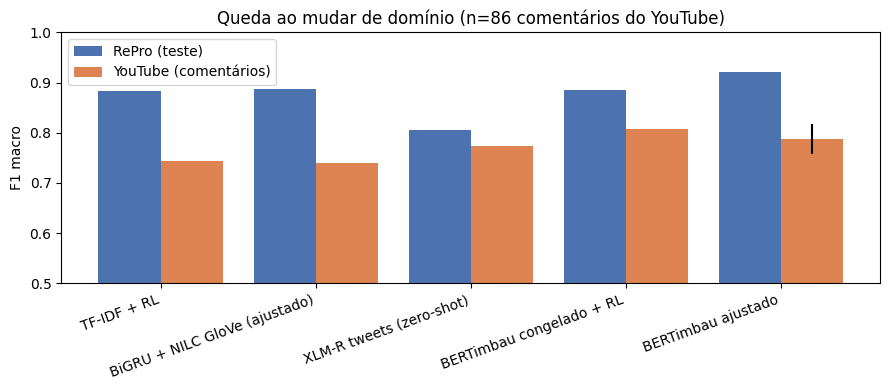

In [4]:
com = res[res["conjunto"] == "comentários"].set_index("modelo")
fig, ax = plt.subplots(figsize=(9, 4))
x = np.arange(len(com))
ax.bar(x - 0.2, com["f1_macro_repro"], 0.4, label="RePro (teste)", color="#4C72B0")
ax.bar(x + 0.2, com["f1_macro"], 0.4, yerr=com["f1_macro_dp"].fillna(0), label="YouTube (comentários)", color="#DD8452")
ax.set_xticks(x, com.index, rotation=20, ha="right"); ax.set_ylim(0.5, 1); ax.set_ylabel("F1 macro")
ax.set_title(f"Queda ao mudar de domínio (n={int(com['n'].iloc[0])} comentários do YouTube)"); ax.legend()
plt.tight_layout(); plt.show()

**Títulos.** Quase todos os títulos com gabarito são neutros (veja a tabela abaixo: 37 de 40). Com só 2 positivos e 1 negativo, o F1 macro dos títulos é instável e serve apenas como ilustração; a acurácia diz mais. Isso confirma a limitação 1 da nota: título é informativo por gênero.

In [5]:
res[res["conjunto"] == "títulos"].round(3)

,conjunto,n,modelo,acuracia,f1_macro,f1_positivo,f1_neutro,f1_negativo,f1_macro_dp,f1_macro_repro
5,títulos,40,TF-IDF + RL,0.300,0.173,0.000,0.440,0.080,NaN,0.883
6,títulos,40,BiGRU + NILC GloVe (ajustado),0.400,0.275,0.154,0.538,0.133,NaN,0.887
7,títulos,40,XLM-R tweets (zero-shot),0.750,0.354,0.000,0.879,0.182,NaN,0.805
8,títulos,40,BERTimbau congelado + RL,0.700,0.332,0.000,0.831,0.167,NaN,0.886
9,títulos,40,BERTimbau ajustado,0.717,0.492,0.467,0.837,0.174,0.07,0.921


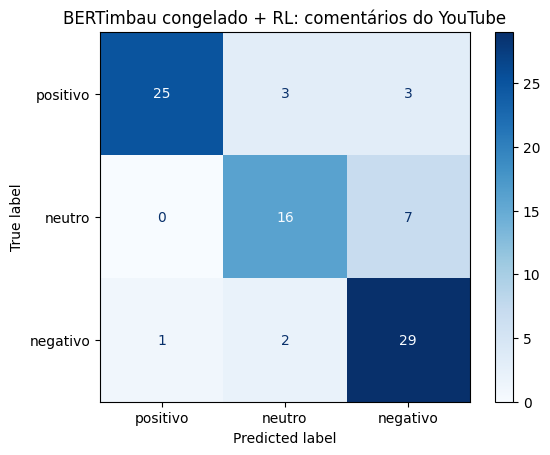

In [6]:
melhor = com["f1_macro"].idxmax()
sub = pred[(pred["tipo"] == "comentário") & pred["rotulo_final"].isin(CLASSES)]
col = melhor if melhor in pred else [c for c in pred if c.startswith(melhor)][0]
ConfusionMatrixDisplay(confusion_matrix(sub["rotulo_final"], sub[col], labels=CLASSES), display_labels=CLASSES).plot(cmap="Blues")
plt.title(f"{col}: comentários do YouTube"); plt.show()

## 3. Ruído: comentários que não são sobre o produto

Nenhum modelo tem a classe "não é sobre o produto", então todos classificam esses comentários em uma das três classes. A tabela mostra a distribuição. Se o app não filtrar esses comentários, eles entram no resumo como se fossem opinião sobre o produto.

In [7]:
ruido = pred[pred["rotulo_final"] == "nao_sobre_produto"]
dist = pd.DataFrame({m: ruido[m].value_counts(normalize=True) for m in MODELOS}).T.reindex(columns=CLASSES).fillna(0)
print(f"{len(ruido)} comentários 'não é sobre o produto'")
dist.round(3)

88 comentários 'não é sobre o produto'


,positivo,neutro,negativo
TF-IDF + RL,0.216,0.193,0.591
BiGRU + NILC GloVe (ajustado),0.307,0.273,0.420
XLM-R tweets (zero-shot),0.432,0.330,0.239
BERTimbau congelado + RL,0.295,0.364,0.341
BERTimbau ajustado (semente 42),0.295,0.341,0.364
BERTimbau ajustado (semente 43),0.239,0.432,0.330
BERTimbau ajustado (semente 44),0.295,0.375,0.330


## 4. Leitura dos resultados

**Desempenho.** Todos os modelos caem ao passar do RePro para os 86 comentários do YouTube. A queda vai de 0,03 no XLM-R (0,805 → 0,774), que não foi treinado no RePro, a 0,15 na BiGRU (0,887 → 0,739) e 0,13 no BERTimbau ajustado (0,921 → 0,788). O BERTimbau congelado + RL cai menos entre os treinados no RePro (0,886 → 0,807) e é o melhor no YouTube, também no neutro (0,727). O neutro continua sendo a classe mais difícil. **Ruído.** O TF-IDF manda 59% dos comentários "não é sobre o produto" para negativo, o que infla as críticas no resumo. Os Transformers espalham o ruído pelas três classes. **Custo.** Na CPU, para 300 comentários: 0,1 s com o TF-IDF, ~3 s com a BiGRU e 50 a 60 s com os Transformers (`05c`). **Limitações.** A amostra é pequena (86 comentários), e as diferenças entre os modelos não são significativas (`05c`). Nos títulos, 37 de 40 são neutros, então o F1 macro não é confiável. O gabarito só tem os itens em que os dois rotuladores concordaram, que tendem a ser os mais fáceis.